Jack Brennan and Austin Blackburn

# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [5]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [6]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.879967,12.534007,S-G1
1,1,osimertinib,B,tago-01560,-1.712741,11.650750,P
2,2,osimertinib,A,tago-02253,12.870441,12.998882,S-G1
3,3,osimertinib,A,tago-01478,15.319292,1.937557,S-syn
4,4,osimertinib,A,tago-02626,13.258777,12.765258,S-G1


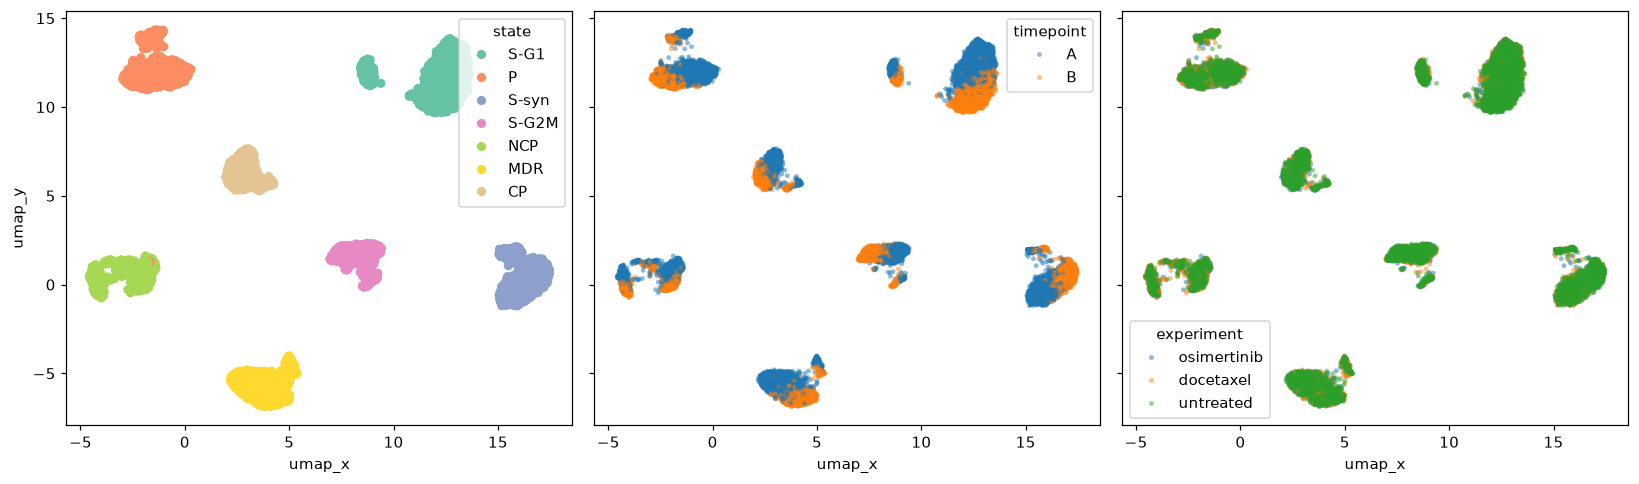

In [7]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [8]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [9]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [10]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [11]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [12]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [13]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

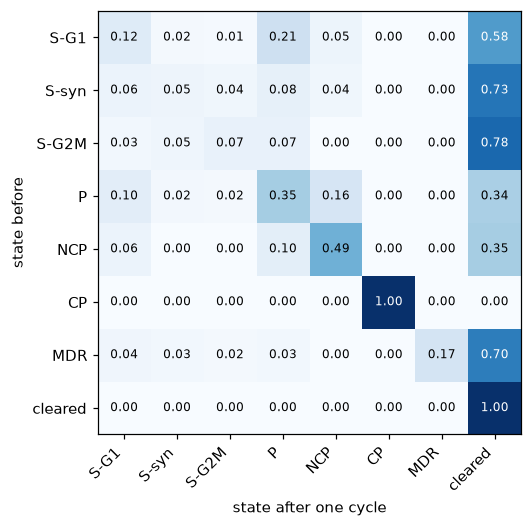

In [14]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

Yes, it seems like CP is absorbing. NCP & P also appear to be sticky, but not absorbing. Absorbing means that CP is completely resistant to osimertinib or that the cell is not responding to the drug. 

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [15]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [16]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [17]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


No, we only clear 98.9% of the cancer.

The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

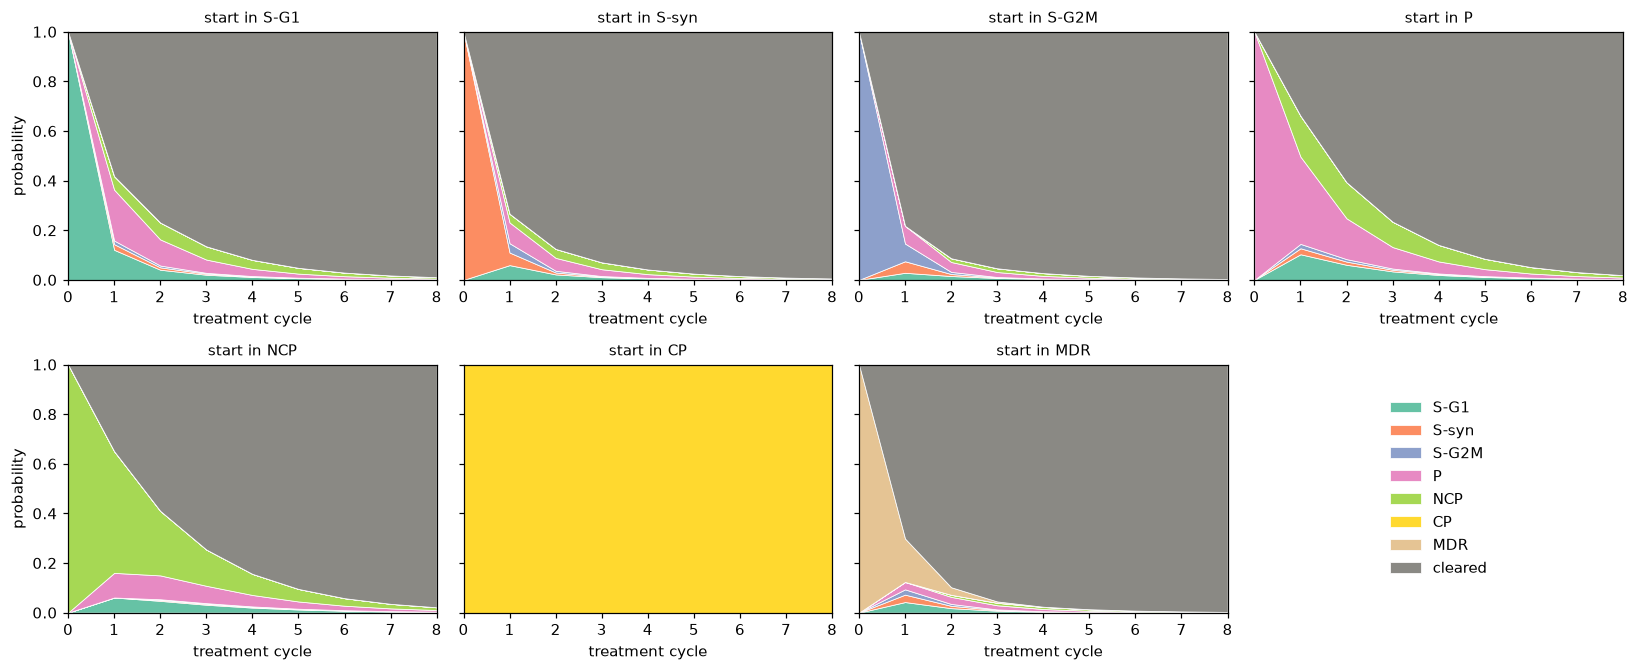

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [18]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



- Osimertinib eliminated every state except for CP (alot of cells had a small percentage still alive, but I considered them effectively cleared). 
- P and NCP lasted the longest at 110 cycles each.
- CP sticks around for the most cycles of drugs. That is because it is absorbing osimertinib.
- CP is the highest at 100% - again, this is ebcause it can absorb osimertinib.

In [19]:
for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, 60)
    alive = 1 - traj[:, -1]
    below_1pct = np.argmax(alive < 0.01) if (alive < 0.01).any() else None
    print(f"{s:6s} alive after 3 cycles: {alive[3]:.3f}   cycles to <1% alive: {below_1pct}")


S-G1   alive after 3 cycles: 0.135   cycles to <1% alive: 9
S-syn  alive after 3 cycles: 0.071   cycles to <1% alive: 7
S-G2M  alive after 3 cycles: 0.047   cycles to <1% alive: 6
P      alive after 3 cycles: 0.234   cycles to <1% alive: 10
NCP    alive after 3 cycles: 0.254   cycles to <1% alive: 10
CP     alive after 3 cycles: 1.000   cycles to <1% alive: None
MDR    alive after 3 cycles: 0.045   cycles to <1% alive: 6


### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

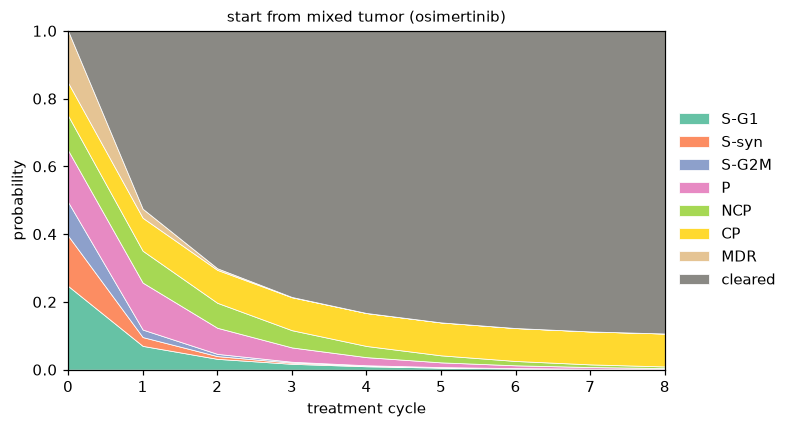

In [20]:
# Your code here

pi_mix = (cells[cells["timepoint"] == "A"]["state"]
          .value_counts(normalize=True)
          .reindex(OUTCOMES, fill_value=0)
          .to_numpy())

# evolve pi_mix and plot the results
evolved_pi_mix_osi = evolve(pi_mix, P_hat, N_CYCLES)

fig, ax = plt.subplots(figsize=(7, 4))
plot_trajectory(evolved_pi_mix_osi, ax, "start from mixed tumor (osimertinib)")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()


<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

- CP ends up dominating the remaining cluster. 
- It doesnt appear like the CP will ever be cleared.
- The endpoint relates to the transition matrix as we see that CP does not lose any cells whereas every other state decreases after every cycle. We see in the tranision matrix that after 1 cycle every state (other than CP) loses mass. We see on this graph that after 8 cycles approx every state other than CP has decreased or decreased to zero. 

In [21]:
long_run = evolve(pi_mix, P_hat, 60)[-1]
pd.Series(long_run, index=OUTCOMES).round(3)

S-G1       0.000
S-syn      0.000
S-G2M      0.000
P          0.000
NCP        0.000
CP         0.097
MDR        0.000
cleared    0.903
dtype: float64

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [22]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
# just created a function bc i have to do it twice lol 
def build_P(experiment):
    df = cells[cells["experiment"] == experiment]
    A = df[df.timepoint == "A"][["lineage_tag", "state"]]
    B = df[df.timepoint == "B"][["lineage_tag", "state"]]
    pairs = pd.merge(A, B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pairs["state_B"] = pairs["state_B"].fillna("cleared")
    counts = (pd.crosstab(pairs.state_A, pairs.state_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    P = counts.div(counts.sum(axis=1), axis=0)
    P.loc["cleared"] = [0] * len(STATES) + [1]   # cleared stays cleared
    return P

P_doc_df = build_P("docetaxel")
P_holiday_df = build_P("untreated")

P_doc = P_doc_df.to_numpy()
P_holiday = P_holiday_df.to_numpy()
P_osi = P_hat.to_numpy()

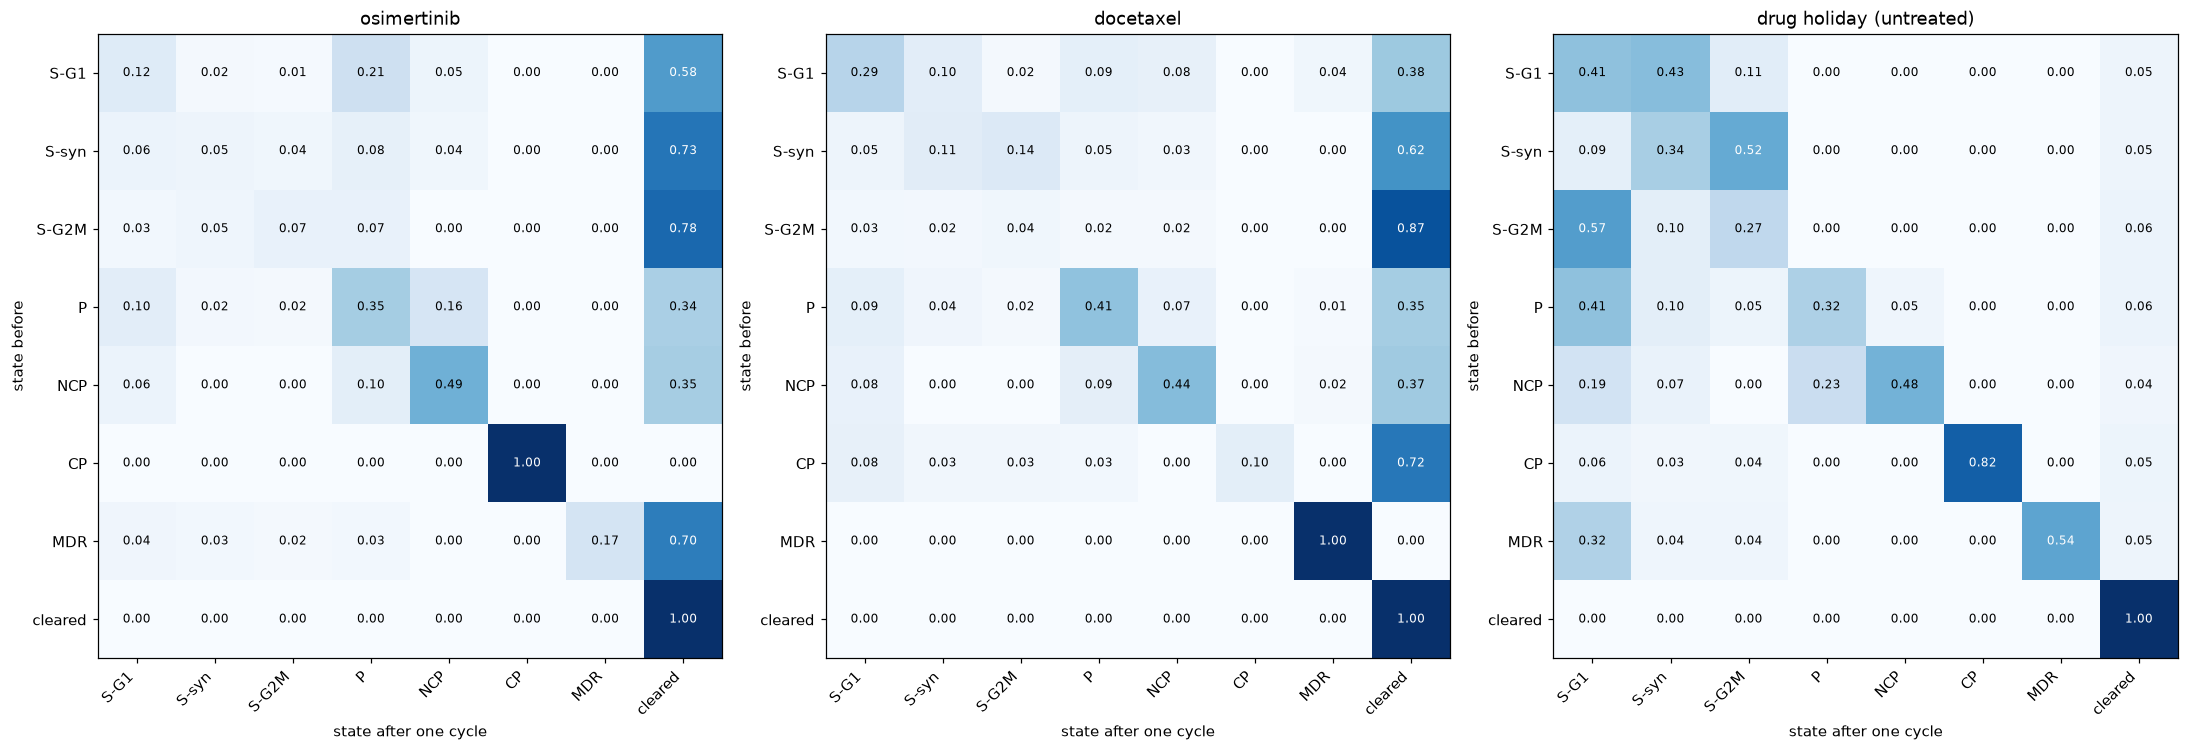

In [23]:
#Plot the transition matrices for osimertinib, docetaxel and drug holiday

fig, axes = plt.subplots(1, 3, figsize=(20, 10))
show_matrix(P_hat,"osimertinib",ax=axes[0])
show_matrix(P_doc_df,"docetaxel",ax=axes[1])
show_matrix(P_holiday_df,"drug holiday (untreated)",ax=axes[2])
plt.tight_layout()
plt.show()

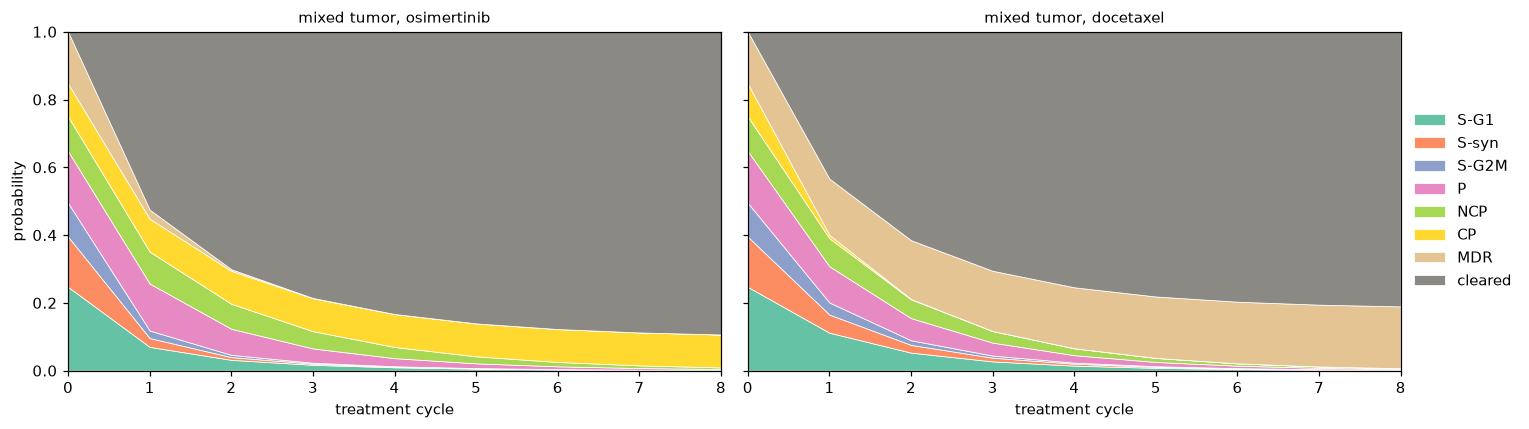

In [24]:
# Simulate the evolution of pi_mix under docetaxel 
evolved_pi_mix_doc = evolve(pi_mix, P_doc, N_CYCLES)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
plot_trajectory(evolved_pi_mix_osi, axes[0], "mixed tumor, osimertinib")
plot_trajectory(evolved_pi_mix_doc, axes[1], "mixed tumor, docetaxel")
axes[0].set_ylabel("probability")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?

The transtion matrix for docetaxel looks very similar to osimertinib. MDR is absorbing (MDR to MDR = 1.00), so docetaxel does not kill MDR cells just like how osimertinib doesn't kill CP. Docetaxel mostly kills CP 72% as compared to osimertinib 0%, but osimertinib kills 70% of MDR and docetaxel kills 0. Docetaxel clears S-G2M best 87%, but otherwise it clears cycling states at similar or slightly lower rates. Compared to drug holiday, there are no absorbing states and only about 4-6% of each state dies per cycle.

2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

The graph shows a similar picture for both docetaxel and osimertinib. For docetaxel all states shrink towards 0 except for MDR as cycles continue. MDR actually seems to increase as cycles continue, suggesting growth in the tumor in those cells due to the treatment. For docetaxel, around 80% of the tumor appears to be cleared with the rest being almost entirely MDR. Compared to CP left from osimertinib (around 10%), the amount of MDR left after multiple cycles of docetaxel is much higher (around 20%).

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [25]:
## Add code here
def run_schedule(pi0, schedule):
    traj = [np.asarray(pi0, dtype=float)]
    for P in schedule:
        traj.append(traj[-1] @ P)
    return np.array(traj)

N = 8
schedules = {
    "osi x8": [P_osi] * N,
    "doc x8": [P_doc] * N,
    "alt osi->doc": [P_osi, P_doc] * (N // 2),
    "alt doc->osi": [P_doc, P_osi] * (N // 2),
}

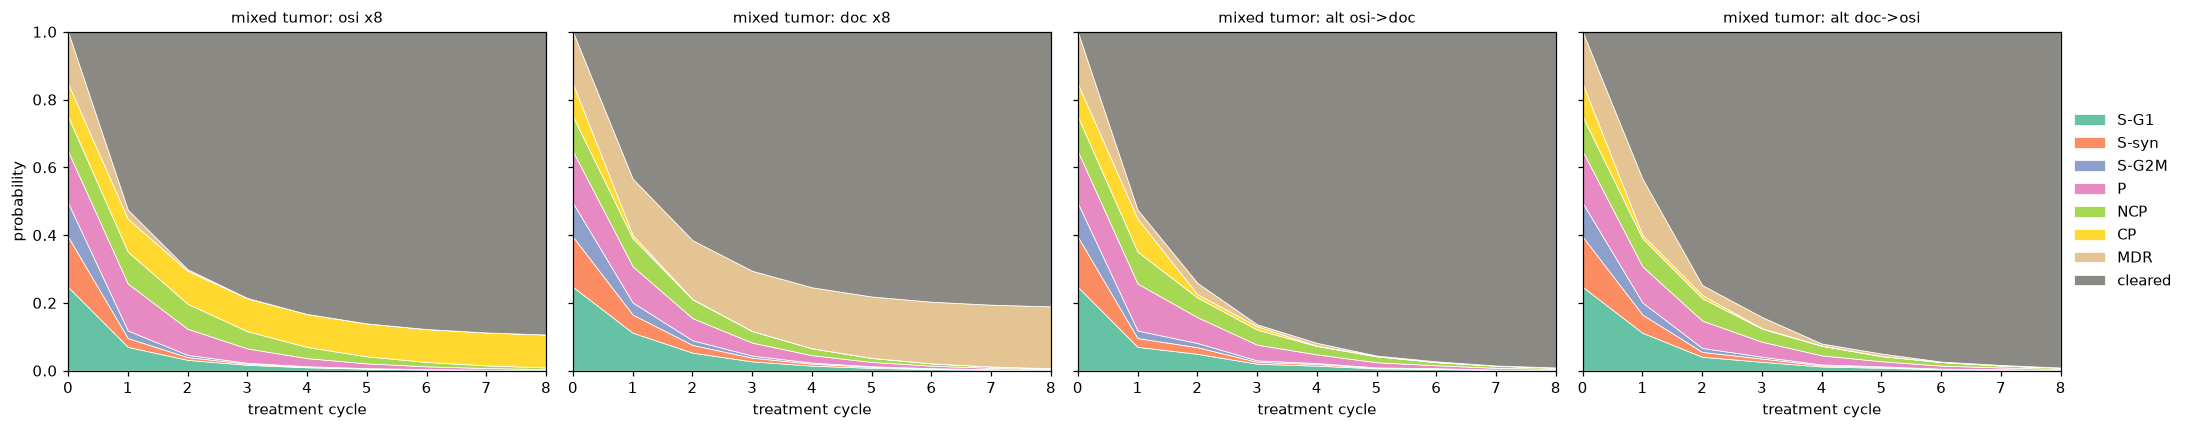

,osi x8,doc x8,alt osi->doc,alt doc->osi
S-G1,0.001,0.002,0.002,0.001
S-syn,0.000,0.001,0.001,0.000
S-G2M,0.000,0.000,0.000,0.000
P,0.003,0.002,0.003,0.003
NCP,0.005,0.002,0.003,0.004
CP,0.097,0.000,0.000,0.000
MDR,0.000,0.183,0.001,0.000
cleared,0.893,0.810,0.991,0.991
alive,0.107,0.190,0.009,0.009


In [26]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, (name, sched) in zip(axes, schedules.items()):
    plot_trajectory(run_schedule(pi_mix, sched), ax, f"mixed tumor: {name}")
axes[0].set_ylabel("probability")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

# final distribution after 8 cycles for each schedule
final = pd.DataFrame({name: run_schedule(pi_mix, sched)[-1]
                      for name, sched in schedules.items()}, index=OUTCOMES)
final.loc["alive"] = 1 - final.loc["cleared"]
final.round(3)

,osi x8,doc x8,alt osi->doc,alt doc->osi
cycle,,,,
0,1.000,1.000,1.000,1.000
1,0.475,0.566,0.475,0.566
2,0.299,0.385,0.259,0.253
3,0.214,0.295,0.137,0.158
4,0.167,0.246,0.082,0.080
5,0.139,0.219,0.045,0.050
6,0.123,0.203,0.027,0.027
7,0.113,0.195,0.015,0.017
8,0.107,0.190,0.009,0.009


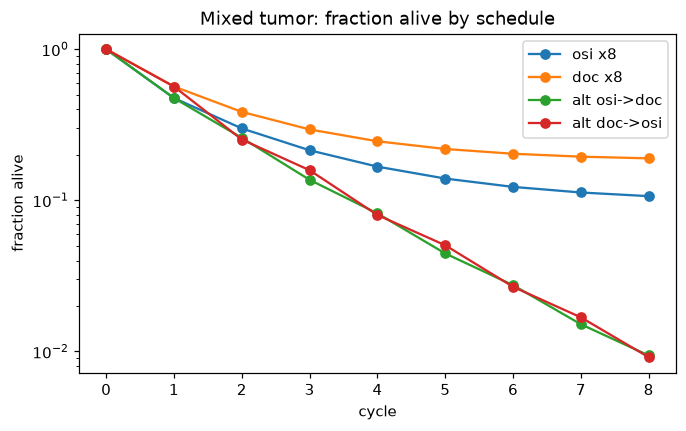

In [27]:
alive = pd.DataFrame({name: 1 - run_schedule(pi_mix, sched)[:, -1]
                      for name, sched in schedules.items()})
alive.index.name = "cycle"
display(alive.round(3))

alive.plot(marker="o", figsize=(7, 4))
plt.ylabel("fraction alive"); plt.yscale("log")
plt.title("Mixed tumor: fraction alive by schedule")
plt.show()

In [28]:
holiday_tests = {
    "doc x8": [P_doc] * 8,
    "doc x4, hol, doc x3": [P_doc] * 4 + [P_holiday] + [P_doc] * 3,
    "doc, hol (x4)": [P_doc, P_holiday] * 4,
    "osi x8": [P_osi] * 8,
    "osi x4, hol, osi x3": [P_osi] * 4 + [P_holiday] + [P_osi] * 3,
    "osi, hol (x4)": [P_osi, P_holiday] * 4,
}

starts = {
    "all MDR": basis("MDR", P_hat),
    "all CP": basis("CP", P_hat),
    "mixed": pi_mix,
}

holiday_results = pd.DataFrame({
    start_name: {sched_name: 1 - run_schedule(pi0, sched)[-1, -1]
                 for sched_name, sched in holiday_tests.items()}
    for start_name, pi0 in starts.items()
})
holiday_results.round(3)        # fraction alive after 8 cycles

,all MDR,all CP,mixed
doc x8,1.000,0.010,0.190
"doc x4, hol, doc x3",0.620,0.009,0.123
"doc, hol (x4)",0.311,0.019,0.093
osi x8,0.003,1.000,0.107
"osi x4, hol, osi x3",0.004,0.832,0.092
"osi, hol (x4)",0.014,0.568,0.084


In [29]:
def rounds_to_clear(pi0, schedule, threshold=0.01):
    '''First cycle at which fraction alive < threshold, or None if never within the schedule.'''
    alive = 1 - run_schedule(pi0, schedule)[:, -1]
    hits = np.where(alive < threshold)[0]
    return int(hits[0]) if len(hits) else None

LONG = 20 # run longer than 8 so we can see how many rounds are needed
plans = {
    "osi": [P_osi] * LONG,
    "doc": [P_doc] * LONG,
    "alt osi->doc": [P_osi, P_doc] * (LONG // 2),
    "alt doc->osi": [P_doc, P_osi] * (LONG // 2),
}

start_vectors = {s: basis(s, P_hat) for s in STATES}
start_vectors["mixed"] = pi_mix

rx = pd.DataFrame({plan: {name: rounds_to_clear(pi0, sched)
                          for name, pi0 in start_vectors.items()}
                   for plan, sched in plans.items()})
rx      # entries = rounds needed to get under 1% alive; None = never (within 20)

,osi,doc,alt osi->doc,alt doc->osi
S-G1,9.0,NaN,8,9
S-syn,7.0,10.0,7,7
S-G2M,6.0,6.0,6,6
P,10.0,NaN,9,9
NCP,10.0,NaN,10,10
CP,NaN,9.0,8,7
MDR,6.0,NaN,7,8
mixed,NaN,NaN,8,8


1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.

Alternating is much better, leaving only 0.009% alive compared to 10.7% with just osimertinib and 19% with just docetaxel. CP and MDR are also reduced to about 0% with alternating as opposed to making up the majority of what was alive without alternating.

2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?

For this tumor, no. Both alternating treatments reduce the tumor to 0.009 after 8 cycles. 

3.  In what situation would a drug holiday help clear the tumor?

A drug holiday would only help if the tumor is at a state the current treatment cannot clear, for example, MDR with docetaxel. When alternating docetaxel with holidays MDR is able to drop from 1 to 0.311. The same occurs for CP when alternating holidays with osimertinib.

4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.


| Tumor makeup | Prescription | Rounds | Reasoning |
|---|---|---|---|
| All S-G1 | Alternating with osimertinib first | 8 | 8 rounds vs 9 for docetaxel first and osimertinib alone, and docetaxel alone never clears it |
| All S-syn | Either Osimertinib or alternating | 7 | Docetaxel takes 10 rounds |
| All S-G2M | Either drug | 6 | Cleared in 6 by both |
| All P | Alternating in either order | 9 | 10 for Osimertinib alone and docetaxel alone never clears it |
| All NCP | Osimertinib or alternating in either order | 10 | Docetaxel alone never clears it |
| All CP | Alternating with docetaxel first | 7 | Osimertinib never clears CP, docetaxel alone takes 9, and alternating with osimertinib first takes 8|
| All MDR | Osimertinib | 6 | Docetaxel never clears MDR |
| Mixed | Alternating in either order | 8 | Each drug alone leaves its absorbing state behind |

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [30]:
rng = np.random.default_rng(100)

In [31]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [32]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

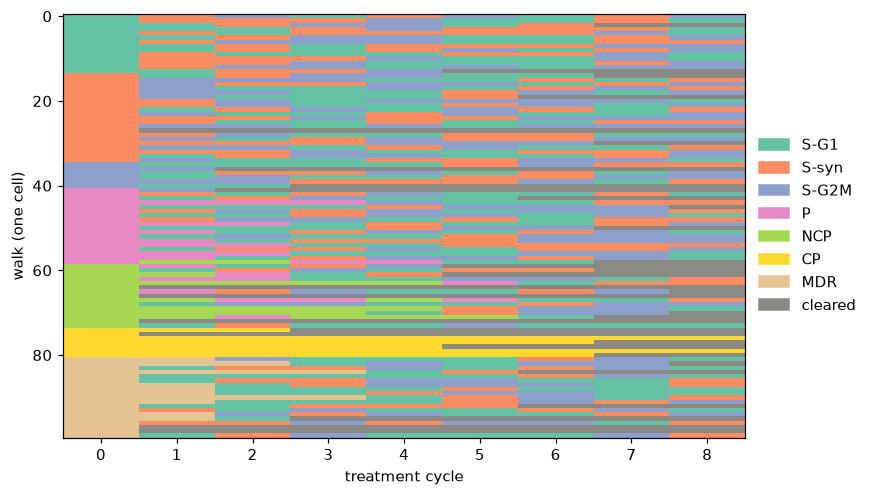

In [33]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [34]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

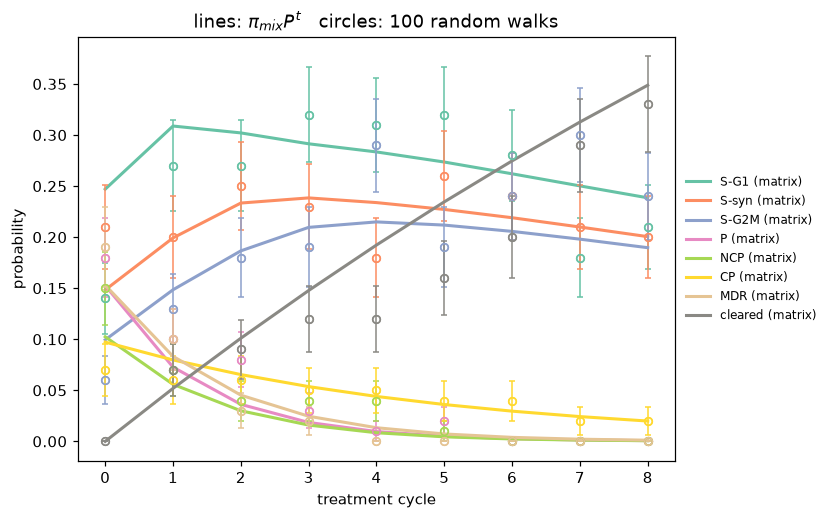

In [35]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

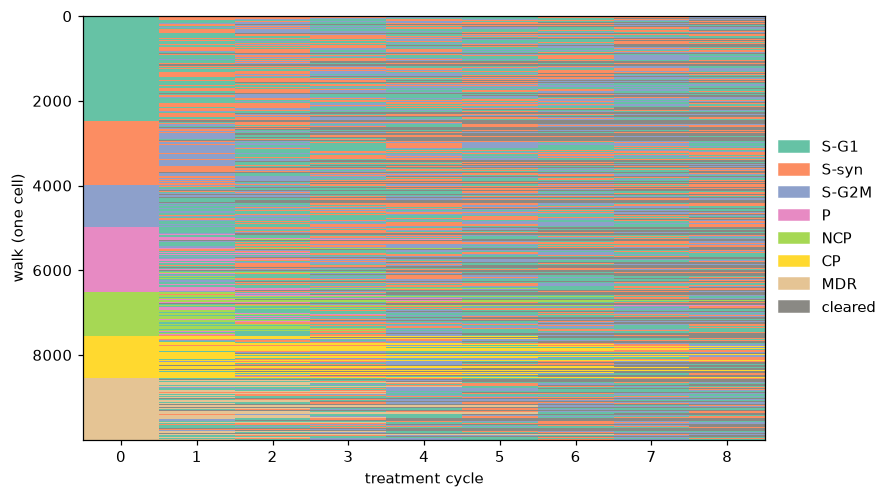

In [36]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [37]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

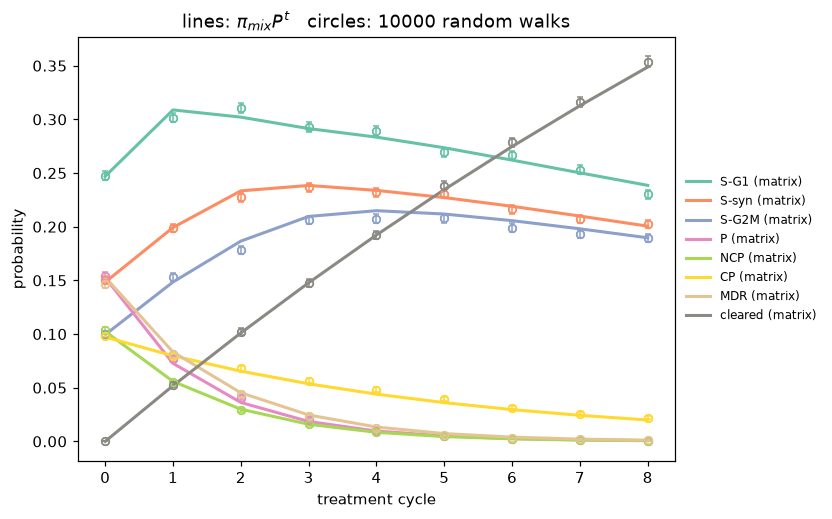

In [38]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

With 10,000 walks, the circles are almost all exactly on the lines and the error bars are shrunk to basically nothing. Since each walk is a random sample, as N increases, the sample means converge to the true probability and the Standard Error shrinks.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [39]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

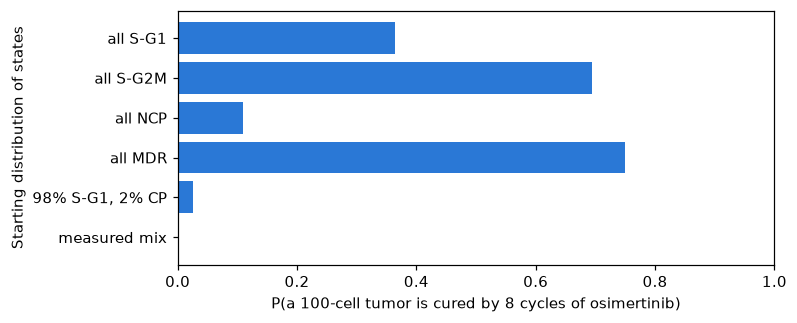

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.025,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.140,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.190,0.638
measured mix,0.000,10.685,0.918


In [40]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

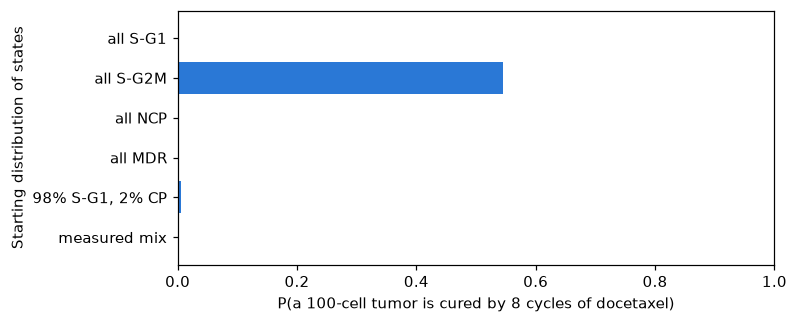

,P(cured),mean surviving cells,share of survivors that are MDR
start,,,
all S-G1,0.000,7.805,0.863
all S-G2M,0.545,0.610,0.631
all NCP,0.000,6.690,0.800
all MDR,0.000,100.000,1.000
"98% S-G1, 2% CP",0.005,6.985,0.866
measured mix,0.000,18.955,0.964


In [41]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of docetaxel
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are MDR":
                     (finals == OUTCOMES.index("MDR")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

The graph shows that docetaxel is worse than osimertinib for almost every starting tumor. It only cures all-S-G2M tumors 54.5% of the time whereas all other tumors are at 0% and never cured. 100% of MDR survives in every tumor since MDR is absorbing under docetaxel as compared osimertinib which clears it 75% of the time.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [ ]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test

def simulate_walks(pi0, schedule, n_cells, rng):
    '''Simulate n_cells random walks at once.
    schedule = list of transition matrices.
    Returns an int array of shape (n_cells, len(schedule) + 1): row = one cell's path.'''
    n_states = len(pi0)
    paths = np.empty((n_cells, len(schedule) + 1), dtype=int)
    paths[:, 0] = rng.choice(n_states, size=n_cells, p=pi0)

    for t, P in enumerate(schedule, start=1):
        cum = np.cumsum(P, axis=1) 
        u = rng.random(n_cells)
        rows = cum[paths[:, t - 1]]
        nxt = (u[:, None] > rows).sum(axis=1)
        paths[:, t] = np.minimum(nxt, n_states - 1)
    return paths

paths = simulate_walks(pi_mix, [P_osi] * 8, 100_000, rng)
check = pd.DataFrame({
    "walks":  [np.mean(paths[:, -1] == j) for j in range(len(OUTCOMES))],
    "matrix": evolve(pi_mix, P_osi, 8)[-1],
}, index=OUTCOMES)
check.round(3)


,walks,matrix
S-G1,0.001,0.001
S-syn,0.000,0.000
S-G2M,0.000,0.000
P,0.003,0.003
NCP,0.005,0.005
CP,0.099,0.097
MDR,0.000,0.000
cleared,0.892,0.893


In [44]:
PERSISTER = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

def longest_persister_run(paths):
    '''For each cell, the longest run of consecutive cycles spent in P or NCP.'''
    in_pers = np.isin(paths[:, 1:], PERSISTER)
    run  = np.zeros(len(paths), dtype=int)
    best = np.zeros(len(paths), dtype=int)
    for t in range(in_pers.shape[1]):
        run  = np.where(in_pers[:, t], run + 1, 0)
        best = np.maximum(best, run)
    return best

def pr_fractions(pi0, schedule, rng, n_tumors=100, n_cells=1000, min_run=3):
    '''Fraction of cells that become permanently resistant, for each simulated tumor.'''
    out = []
    for _ in range(n_tumors):
        paths = simulate_walks(pi0, schedule, n_cells, rng)
        out.append(np.mean(longest_persister_run(paths) >= min_run))
    return np.array(out)

fr_osi = pr_fractions(pi_mix, [P_osi] * 8, rng)

osimertinib, 8 cycles: PR fraction = 0.0840 ± 0.0009 (SEM)
95% CI: (0.0823, 0.0858)
t = -17.92, p = 7.61e-33


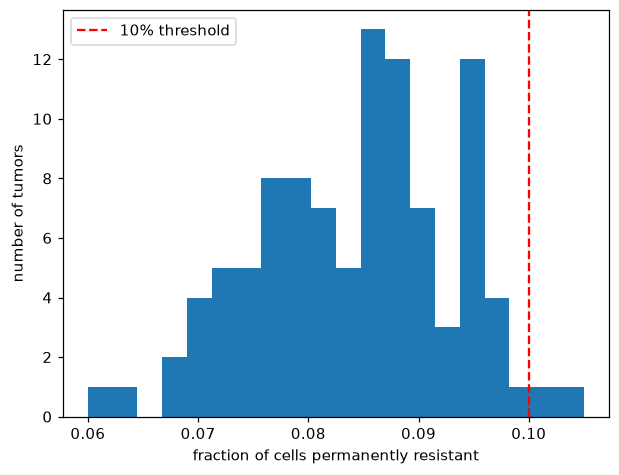

In [45]:
from scipy import stats

mean = fr_osi.mean()
sem  = fr_osi.std(ddof=1) / np.sqrt(len(fr_osi))
ci   = (mean - 1.96 * sem, mean + 1.96 * sem)
print(f"osimertinib, 8 cycles: PR fraction = {mean:.4f} ± {sem:.4f} (SEM)")
print(f"95% CI: ({ci[0]:.4f}, {ci[1]:.4f})")

# one-sample t-test against 10%
t, p = stats.ttest_1samp(fr_osi, 0.10)
print(f"t = {t:.2f}, p = {p:.3g}")

plt.hist(fr_osi, bins=20)
plt.axvline(0.10, color="red", ls="--", label="10% threshold")
plt.xlabel("fraction of cells permanently resistant"); plt.ylabel("number of tumors")
plt.legend(); plt.show()

<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

% of tumors with > 10% permanently resistant cells


,osimertinib alone,docetaxel alone,alternating O/D,docetaxel + holiday
cycles,,,,
2,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0
8,2.0,0.0,1.0,0.0
10,2.0,0.0,0.0,0.0
12,4.0,0.0,0.0,0.0


mean PR fraction per tumor


,osimertinib alone,docetaxel alone,alternating O/D,docetaxel + holiday
cycles,,,,
2,0.0000,0.0000,0.0000,0.0000
4,0.0763,0.0540,0.0674,0.0489
6,0.0818,0.0579,0.0759,0.0605
8,0.0830,0.0593,0.0753,0.0653
10,0.0838,0.0606,0.0772,0.0674
12,0.0818,0.0598,0.0771,0.0697


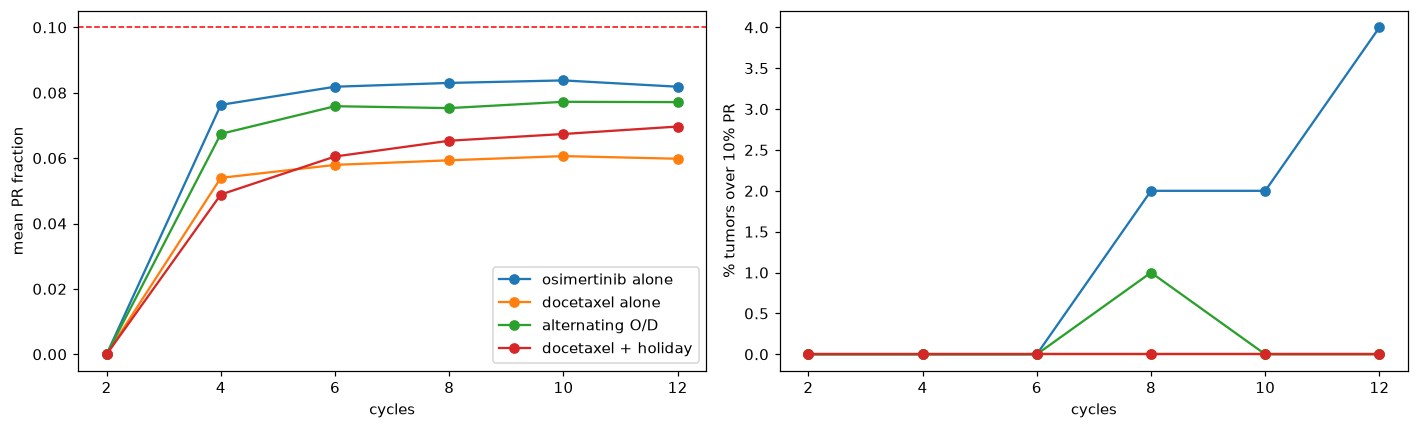

In [46]:
def make_schedule(drugs, n):
    '''Repeat a pattern of matrices out to exactly n cycles (works for odd n too).'''
    return [drugs[i % len(drugs)] for i in range(n)]

treatments = {
    "osimertinib alone": [P_osi],
    "docetaxel alone": [P_doc],
    "alternating O/D": [P_osi, P_doc],
    "docetaxel + holiday": [P_doc, P_holiday],
}
cycle_counts = [2, 4, 6, 8, 10, 12]

pct_over, mean_pr = {}, {}
for name, drugs in treatments.items():
    pct_over[name], mean_pr[name] = {}, {}
    for n in cycle_counts:
        fr = pr_fractions(pi_mix, make_schedule(drugs, n), rng)
        pct_over[name][n] = 100 * np.mean(fr > 0.10)
        mean_pr[name][n]  = fr.mean()

pct_over = pd.DataFrame(pct_over); pct_over.index.name = "cycles"
mean_pr  = pd.DataFrame(mean_pr);  mean_pr.index.name = "cycles"

print("% of tumors with > 10% permanently resistant cells")
display(pct_over.round(1))
print("mean PR fraction per tumor")
display(mean_pr.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mean_pr.plot(marker="o", ax=axes[0])
axes[0].axhline(0.10, color="red", ls="--", lw=1)
axes[0].set_ylabel("mean PR fraction")
pct_over.plot(marker="o", ax=axes[1], legend=False)
axes[1].set_ylabel("% tumors over 10% PR")
plt.tight_layout(); plt.show()

Only a few tumors exceed 10% permanently resistant (PR) cells under any treatment. Only osimertinib alone (2% of tumors at 8 and 10 cycles, 4% at 12) and alternating O/D (1% at 8 cycles) ever cross the threshold. This is because the mean amount of PR cells stays below 10% for every treatment: about 0.083 for osimertinib, 0.075 for alternating, 0.060 for docetaxel, and 0.070 for docetaxel + holiday at 8–12 cycles. The few tumors over 10% are random draws from the upper tail. Osimertinib produces the most PR cells because it puts the most cells into persister states. As the number of cycles increases, PR cells cannot form before cycle 3 so it is 0 at 2 cycles and then rises by cycle 4 and levels off for the drug-only schedules, since by about cycle 6 most persisters have been cleared. Docetaxel + holiday is the exception since it keeps climbing because holiday cycles kill basically nothing.

AI Use Note: Claude was used to help with coding syntax and brainstorming when creating some graphs and tables in this lab.